## Introduction to Decision Tree

Decision Tree is a supervised machine learning algorithm used for classification and regression tasks. It works like a flowchart, dividing data into smaller groups based on different features and decision rules. Each internal node represents a decision, branches represent possible outcomes, and leaf nodes provide the final prediction. In this project, a Decision Tree Regressor is used with the medical insurance dataset to predict insurance charges based on features such as age, BMI, smoking status, and other personal details. The model is trained on existing data and evaluated using metrics such as MAE, MSE, RMSE, and R² score.

In [1]:
import pandas as pd

df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
print(df.shape)

(1338, 7)


In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None


In [4]:
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


**CHECKING DATA VISUALLY**


In [5]:
df.describe()


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


**SEPARATING X AND Y**

In [6]:
X = df.drop("charges", axis=1)
y = df["charges"]

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1338, 6)
y shape: (1338,)


80% → Training data

The Decision Tree learns from this.

20% → Testing data

We use this later to see how well it predicts new data.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
print("Training data:", X_train.shape) #learning data 
print("Testing data:", X_test.shape) # checking data

Training data: (1070, 6)
Testing data: (268, 6)


**model = DecisionTreeRegressor(random_state=42)**

This line basically means 
Create a Decision Tree model that will predict a numerical value


In [11]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(random_state=42)

Create the model

       ↓

Train the model

       ↓

Make predictions

       ↓
       
Evaluate it

In [13]:
df = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True
)

In [14]:
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [15]:
X = df.drop("charges", axis=1)
y = df["charges"]

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

**TRAINING THE DECISION TREE**

In [17]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

X_train + y_train

        ↓

     .fit()

        ↓
        
  Model learns

In [18]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[ 9225.2564   5266.3656  28950.4692   9225.2564  33732.6867  11326.71487
  2527.81865 14410.9321   2974.126   10702.6424 ]


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3384.4735150597016
MSE: 47076628.89628262
RMSE: 6861.241060936616
R2 Score: 0.6967664183537811


Metric	Easy meaning
MAE	Average size of the prediction errors
MSE	Average squared prediction error
RMSE	Prediction error in the original charges units
R² Score	How well the model explains variations in insurance charges


- MAE: Lower is better.
- MSE: Lower is better.
- RMSE: Lower is better.
- R²: Generally, closer to 1 is better.
Because a Decision Tree can memorize training data, we evaluate it on X_test rather than relying on training performance alone.

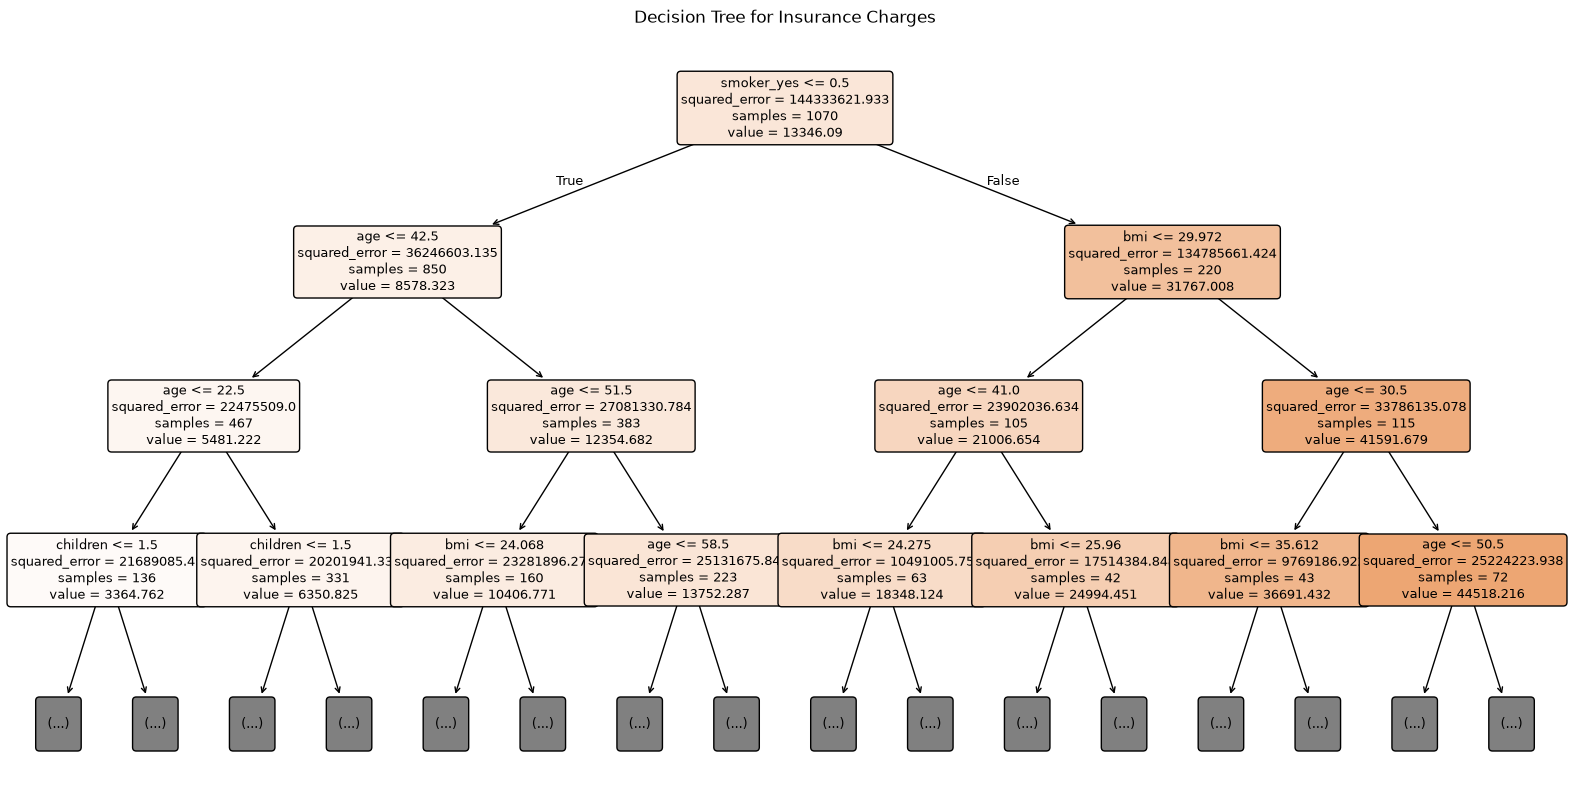

In [20]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree for Insurance Charges")
plt.show()

1. What is your Decision Tree doing?
Your project uses the Medical Insurance dataset to predict a person's insurance charges based on their information.

Input features: age, BMI, number of children, smoking status, sex, and region.

Target: charges — the insurance cost we want to predict.

Model: DecisionTreeRegressor

Type of problem: Supervised learning → Regression, because we predict a numerical amount.

The tree learns rules from the training data and uses those rules to predict insurance charges for new people.

2. How to read your tree
Look at the very first box at the top.

Root node — first decision


smoker_yes <= 0.5

This is the first question your model asks.

True (left branch): smoker_yes is 0, meaning the person is a non-smoker.

False (right branch): smoker_yes is 1, meaning the person is a smoker.

Your tree begins by separating people according to smoking status because this split helps reduce the prediction errors in the training data.

This is the most important observation from your diagram: smoking status is the first feature your trained tree uses to divide the data.

3. Understand the numbers inside each box
Let's take the top box in your actual diagram:

Root node explained
From your Decision Tree

smoker_yes <= 0.5

squared_error = 144333621.933

samples = 1070

value = 13346.09

samples = 1070

There are 1,070 training records at this node.

value = 13346.09

The average actual insurance charge of those training records is approximately 13,346.09. This is the prediction at this node.

squared_error = 144333621.933

It measures how spread out the actual charges are around the average. A smaller value means the charges are less spread out.

4. Follow the branches of your tree
Your tree divides the data into smaller groups as it moves downward.

Branch A — Non-smokers
Left side
Your diagram shows:

Value = 8578.323
The tree has 850 training records in this group. Its next question is:

age <= 42.5

True: the person is 42.5 years old or younger.

False: the person is older than 42.5.

The tree then divides these groups further using age, number of children, and BMI.

Branch B — Smokers
Right side
Your diagram shows:

Value = 31767.008
The tree has 220 training records in this group. Its next question is:

bmi <= 29.972

True: BMI is 29.972 or lower.

False: BMI is greater than 29.972.

The tree then uses age and BMI to divide the smokers into smaller groups.

What does this tell us?

In your training data, the average charges at the smoker node are much higher than at the non-smoker node. The tree uses this information to help predict charges. These values are averages for the groups, not the exact charges for every individual.

5. Why are there so many boxes?
Each box represents a decision or a group of records.

The top box is called the root node.

The boxes in the middle are decision nodes.

The final boxes are called leaf nodes. They provide the final predicted insurance charge.

For example, a person might follow this path:

Non-smoker → Age ≤ 42.5 → Age ≤ 22.5 → Children ≤ 1.5

The tree continues following the conditions until it reaches a leaf, where it produces a numerical prediction.

The (...) boxes at the bottom of your diagram mean that additional branches have been hidden from the visualization.

Your plotting code uses max_depth=3, so the diagram displays only a limited part of the tree. It does not mean that your trained model has been reduced to that depth.

6. How does the tree decide which split to use?
Your model is a DecisionTreeRegressor.

It tests possible splits and looks for ones that reduce the variation in insurance charges within the resulting groups. In your diagram, the first split is based on smoker_yes.

As the tree creates more branches, it tries to make the charges within each group more similar, helping it make more specific predictions.

In [21]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 2697.76543053848
RMSE: 4592.764309715603
R2 Score: 0.8641310379678357


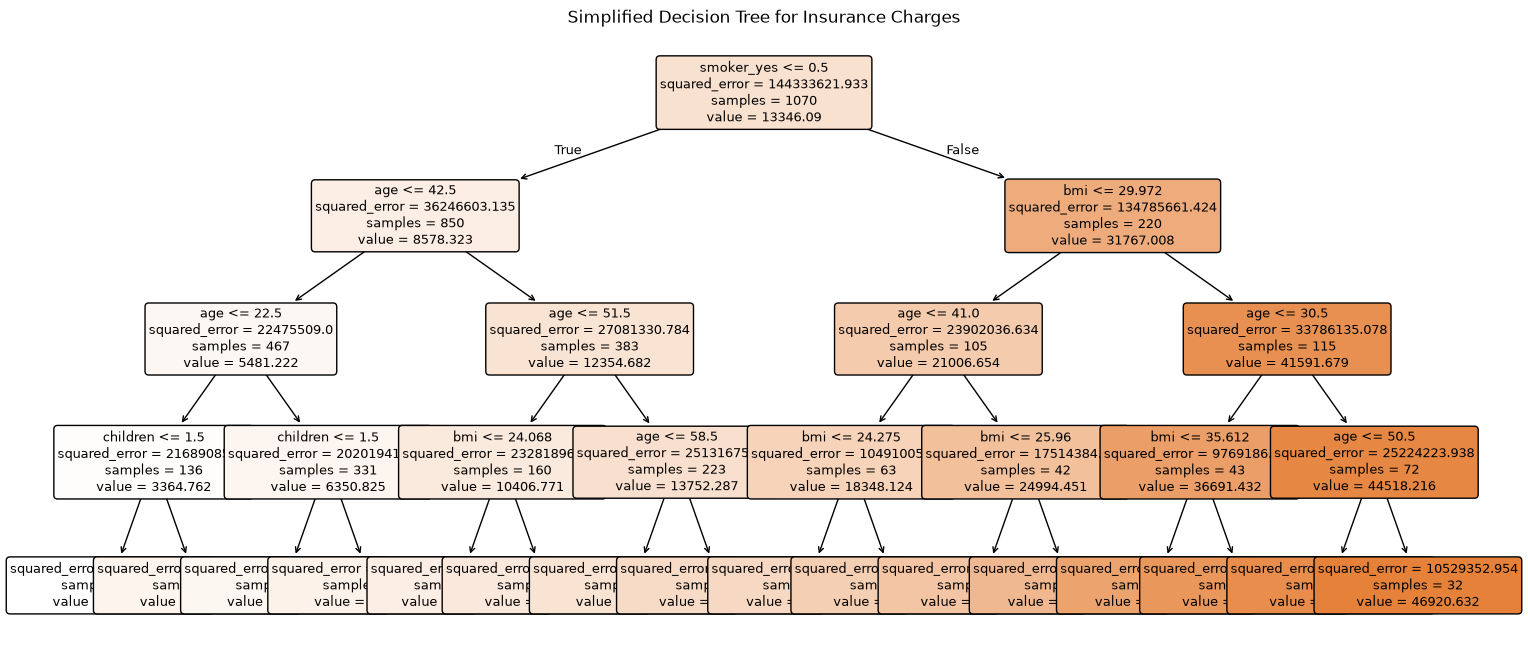

In [23]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Simplified Decision Tree for Insurance Charges")
plt.show()

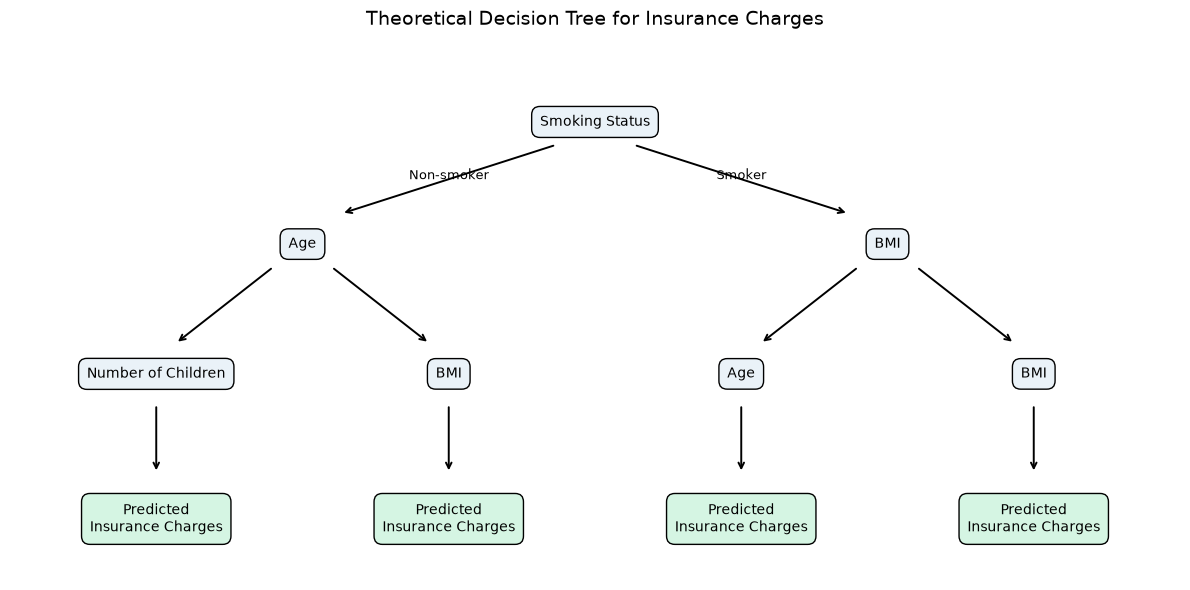

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis("off")

def draw_box(x, y, text, color="#EAF2F8"):
    ax.text(
        x, y, text,
        ha="center", va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor=color,
            edgecolor="black"
        )
    )

def draw_arrow(x1, y1, x2, y2, label=""):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.4)
    )
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2,
                label, fontsize=9, ha="center")

# Root node
draw_box(6, 6, "Smoking Status")

# Second level
draw_box(3, 4.4, "Age")
draw_box(9, 4.4, "BMI")

draw_arrow(5.6, 5.7, 3.4, 4.8, "Non-smoker")
draw_arrow(6.4, 5.7, 8.6, 4.8, "Smoker")

# Third level
draw_box(1.5, 2.7, "Number of Children")
draw_box(4.5, 2.7, "BMI")
draw_box(7.5, 2.7, "Age")
draw_box(10.5, 2.7, "BMI")

draw_arrow(2.7, 4.1, 1.7, 3.1)
draw_arrow(3.3, 4.1, 4.3, 3.1)
draw_arrow(8.7, 4.1, 7.7, 3.1)
draw_arrow(9.3, 4.1, 10.3, 3.1)

# Prediction nodes
draw_box(1.5, 0.8, "Predicted\nInsurance Charges", "#D5F5E3")
draw_box(4.5, 0.8, "Predicted\nInsurance Charges", "#D5F5E3")
draw_box(7.5, 0.8, "Predicted\nInsurance Charges", "#D5F5E3")
draw_box(10.5, 0.8, "Predicted\nInsurance Charges", "#D5F5E3")

draw_arrow(1.5, 2.3, 1.5, 1.4)
draw_arrow(4.5, 2.3, 4.5, 1.4)
draw_arrow(7.5, 2.3, 7.5, 1.4)
draw_arrow(10.5, 2.3, 10.5, 1.4)

plt.title("Theoretical Decision Tree for Insurance Charges",
          fontsize=14, pad=15)

plt.tight_layout()
plt.show()

- Root node: Smoking Status
- Decision nodes: Age, BMI, and Number of Children
- Leaf nodes: Predicted Insurance Charges
This is a conceptual illustration, not the exact learned structure of your trained model. It contains no numerical thresholds or model statistics.